<a href="https://colab.research.google.com/github/kangyeson/AI-Class/blob/main/1026/car_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
# 구글 드라이브 마운트
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

import torch
import torch.nn as nn

sns.set_theme(style="whitegrid")

# 1. 데이터 구조 확인

In [24]:
# 데이터 불러오기 (car.data에는 열 이름이 없으므로 직접 지정)
column_names = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/car.data", names=column_names)

print("데이터 크기:", df.shape)

print("\n처음 5개 데이터")
display(df.head())

print("\n데이터 정보")
df.info()

데이터 크기: (1728, 7)

처음 5개 데이터


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc



데이터 정보
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


**확인 결과**: 1,728행 × 7열, 7개 변수 모두 문자(object)형 → 모델에 넣으려면 숫자로 바꿔야 함

# 2. 결측치와 중복 데이터 확인

In [25]:
print("변수별 결측치 개수")
print(df.isnull().sum())

print("\n중복 행 개수")
print(df.duplicated().sum())

변수별 결측치 개수
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

중복 행 개수
0


**확인 결과**: 모든 변수의 결측치 0개, 중복 행 0개 → 별도 처리 필요 없음

# 3. 변수별 값 종류와 개수 확인

In [26]:
for col in column_names:
    print(f"\n[{col}]")
    print(df[col].value_counts())


[buying]
buying
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64

[maint]
maint
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64

[doors]
doors
2        432
3        432
4        432
5more    432
Name: count, dtype: int64

[persons]
persons
2       576
4       576
more    576
Name: count, dtype: int64

[lug_boot]
lug_boot
small    576
med      576
big      576
Name: count, dtype: int64

[safety]
safety
low     576
med     576
high    576
Name: count, dtype: int64

[class]
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


**확인 결과**
- 입력 변수 6개는 값마다 개수가 똑같음 (432개 또는 576개)
- 1,728 = 4 × 4 × 4 × 3 × 3 × 3 → 가능한 모든 조합이 정확히 한 번씩 들어 있는 데이터

# 4. 레이블(class) 개수 확인

In [27]:
print("레이블 종류")
print(df['class'].unique())

print("\n레이블별 개수")
print(df['class'].value_counts())

print("\n레이블별 비율(%)")
print((df['class'].value_counts(normalize=True) * 100).round(2))

레이블 종류
['unacc' 'acc' 'vgood' 'good']

레이블별 개수
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

레이블별 비율(%)
class
unacc    70.02
acc      22.22
good      3.99
vgood     3.76
Name: proportion, dtype: float64


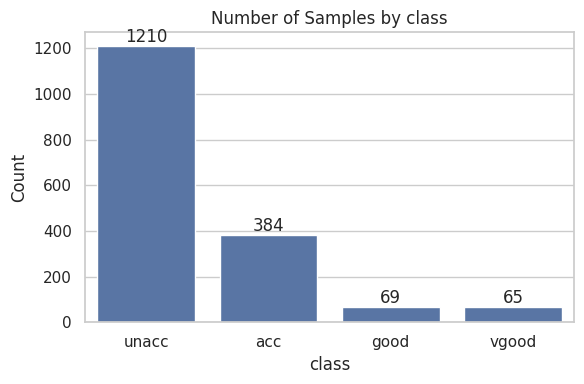

In [28]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(
    data=df,
    x='class',
    order=['unacc', 'acc', 'good', 'vgood']
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Number of Samples by class")
plt.xlabel("class")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

**확인 결과**
- 레이블 종류: unacc, acc, good, vgood (4개)
- unacc 1,210개(70%), acc 384개(22%), good 69개(4%), vgood 65개(4%) → **클래스 불균형이 심함**
- 비어있는 클래스는 없지만, good과 vgood은 데이터가 매우 적음 → 이 두 등급은 맞히기 어려울 수 있음

# 5. 범주형 → 숫자 변환
크기 순서가 있는 값들이므로, 작은 것부터 0, 1, 2, ... 순서대로 숫자를 매긴다.
(LabelEncoder는 알파벳 순서로 번호를 매겨 high=0, low=1처럼 크기 순서가 뒤섞이므로 사용하지 않음)

In [29]:
price_dict = {'low': 0, 'med': 1, 'high': 2, 'vhigh': 3}
doors_dict = {'2': 0, '3': 1, '4': 2, '5more': 3}
persons_dict = {'2': 0, '4': 1, 'more': 2}
lug_dict = {'small': 0, 'med': 1, 'big': 2}
safety_dict = {'low': 0, 'med': 1, 'high': 2}
class_dict = {'unacc': 0, 'acc': 1, 'good': 2, 'vgood': 3}

df['buying'] = df['buying'].map(price_dict)
df['maint'] = df['maint'].map(price_dict)
df['doors'] = df['doors'].map(doors_dict)
df['persons'] = df['persons'].map(persons_dict)
df['lug_boot'] = df['lug_boot'].map(lug_dict)
df['safety'] = df['safety'].map(safety_dict)
df['class'] = df['class'].map(class_dict)

display(df.head())

print("\n변환 후 결측치 개수 (매핑이 잘 됐는지 확인)")
print(df.isnull().sum())

,buying,maint,doors,persons,lug_boot,safety,class
0,3,3,0,0,0,0,0
1,3,3,0,0,0,1,0
2,3,3,0,0,0,2,0
3,3,3,0,0,1,0,0
4,3,3,0,0,1,1,0



변환 후 결측치 개수 (매핑이 잘 됐는지 확인)
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


**확인 결과**: 매핑 후에도 결측치가 0개 → 모든 값이 빠짐없이 숫자로 바뀜 (dict에 없는 값이 있으면 결측치가 생김)

# 6. 입력 변수별 클래스 분포 확인

In [30]:
target_col = 'class'
feature_cols = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']

for col in feature_cols:
    print(f"\n[{col}]별 class 평균")
    print(df.groupby(col)[target_col].mean().round(3))


[buying]별 class 평균
buying
0    0.690
1    0.553
2    0.250
3    0.167
Name: class, dtype: float64

[maint]별 class 평균
maint
0    0.606
1    0.553
2    0.333
3    0.167
Name: class, dtype: float64

[doors]별 class 평균
doors
0    0.326
1    0.417
2    0.458
3    0.458
Name: class, dtype: float64

[persons]별 class 평균
persons
0    0.000
1    0.625
2    0.620
Name: class, dtype: float64

[lug_boot]별 class 평균
lug_boot
0    0.255
1    0.448
2    0.542
Name: class, dtype: float64

[safety]별 class 평균
safety
0    0.000
1    0.448
2    0.797
Name: class, dtype: float64


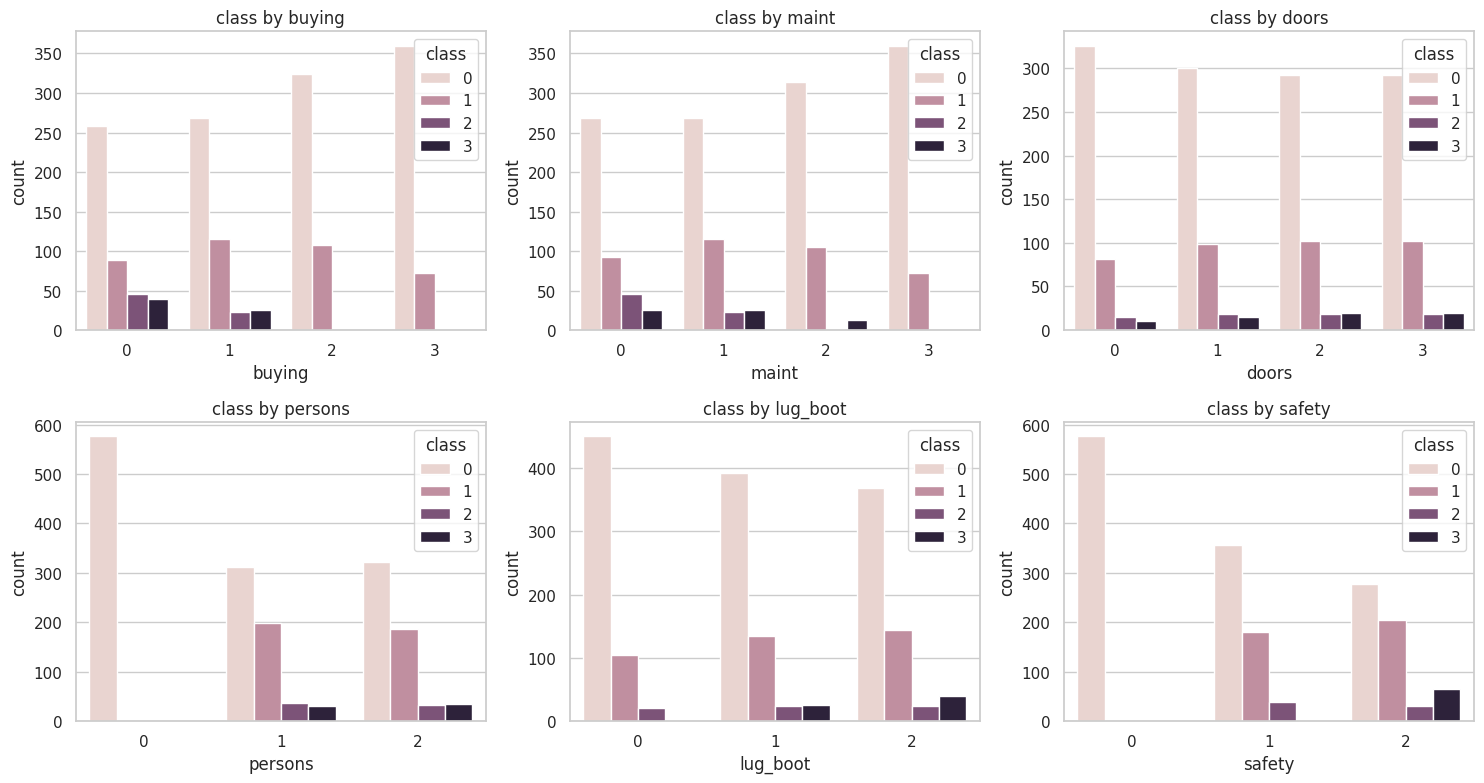

In [31]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
axs = axs.flatten()

for i, col in enumerate(feature_cols):
    sns.countplot(data=df, x=col, hue=target_col, ax=axs[i])
    axs[i].set_title(f"class by {col}")

plt.tight_layout()
plt.show()

**확인 결과**
- **safety = low(0)이면 class 평균 0** → 안전성이 낮으면 무조건 unacc
- **persons = 2(0)이면 class 평균 0** → 2인승이면 무조건 unacc
- buying, maint는 가격이 낮을수록 class 평균이 높음 (싸면 평가가 좋음)
- safety, lug_boot는 클수록 class 평균이 높음
- doors는 클래스 평균 차이가 작음 → 영향이 적음

# 7. 상관관계 분석

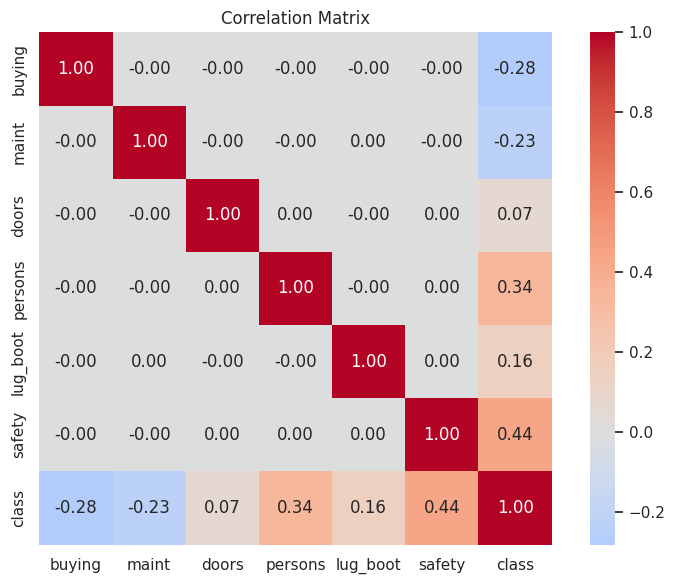

In [32]:
plt.figure(figsize=(8, 6))

sns.heatmap(df.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

**확인 결과**
- class와 상관관계: safety(0.44) > persons(0.34) > buying(-0.28) > maint(-0.23) > lug_boot(0.16) > doors(0.07)
- 입력 변수끼리의 상관관계는 모두 0 → 모든 조합이 한 번씩 들어있는 데이터라서 변수끼리는 서로 독립

# 8. 학습 데이터 준비
- 입력: 6개 변수 전체
- 레이블: class → 원-핫 인코딩
- 8:2로 분할 (클래스 불균형이 크므로 stratify로 비율 유지) 후 StandardScaler로 표준화

In [33]:
X = df[feature_cols].values
y = df[target_col].values

# 정답 레이블 원-핫 인코딩
encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(y.reshape(-1, 1))

print("원-핫 인코딩 결과:")
print(y_onehot[:5])
print("원-핫 인코딩 shape:", y_onehot.shape)

# 학습 데이터와 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y_onehot,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 표준화
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nTrain:", X_train.shape, " Test:", X_test.shape)

원-핫 인코딩 결과:
[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]]
원-핫 인코딩 shape: (1728, 4)

Train: (1382, 6)  Test: (346, 6)


# 9. 기준선 (Baseline): 전부 unacc(0)로 예측
전체의 70%가 unacc이므로, 무조건 0으로만 예측해도 Accuracy가 약 70%가 나온다.
모델은 최소한 이것보다 좋아야 의미가 있다.

In [34]:
y_train_label = y_train.argmax(axis=1)      # 원-핫 → 원래 레이블(0~3)
y_test_label = y_test.argmax(axis=1)

baseline_preds = [0] * len(y_test_label)
baseline_acc = accuracy_score(y_test_label, baseline_preds)

print(f"Baseline Accuracy: {baseline_acc * 100:.2f}%")

Baseline Accuracy: 69.94%


# 10. 기본 분류 모델: Random Forest
신경망과 비교하기 위한 기본 모델. 원-핫이 아닌 원래 레이블(0~3)로 학습한다.

In [35]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train_label)

rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test_label, rf_pred)

print(f"Random Forest Accuracy: {rf_acc * 100:.2f}%")
print(classification_report(y_test_label, rf_pred))

Random Forest Accuracy: 96.53%
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       242
           1       0.92      0.95      0.94        77
           2       0.91      0.71      0.80        14
           3       0.80      0.92      0.86        13

    accuracy                           0.97       346
   macro avg       0.91      0.89      0.90       346
weighted avg       0.97      0.97      0.97       346



**확인 결과**
- Accuracy 약 96.5% → Baseline(약 70%)보다 훨씬 높음
- unacc(0)는 거의 100%, acc(1)도 90% 이상
- good(2)의 recall이 약 0.71로 가장 낮음 → 실제 good 14개 중 약 4개를 다른 등급으로 예측
  - precision: 그 클래스라고 예측한 것 중 실제로 맞은 비율
  - recall: 실제 그 클래스인 것 중 맞게 찾아낸 비율

# 11. 인공신경망 분류 모델

In [36]:
# NumPy -> PyTorch Tensor
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

In [37]:
# 신경망 모델 정의
class CarModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(6, 128),
            nn.ReLU(),
            nn.Linear(128, 4)         # 마지막 층: 클래스 4개, activation 없음
        )

    def forward(self, x):
        return self.network(x)

model = CarModel()

In [38]:
# Loss와 Optimizer 설정
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 모델 학습
epochs = 1000
loss_history = []

for epoch in range(epochs):
    model.train()

    # 예측
    outputs = model(X_train)

    # MSE Loss 계산
    loss = criterion(outputs, y_train)

    # 역전파 및 가중치 업데이트
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [100/1000], Loss: 0.0594
Epoch [200/1000], Loss: 0.0487
Epoch [300/1000], Loss: 0.0408
Epoch [400/1000], Loss: 0.0343
Epoch [500/1000], Loss: 0.0292
Epoch [600/1000], Loss: 0.0257
Epoch [700/1000], Loss: 0.0232
Epoch [800/1000], Loss: 0.0213
Epoch [900/1000], Loss: 0.0197
Epoch [1000/1000], Loss: 0.0183


In [39]:
# 테스트 데이터 평가
model.eval()

with torch.no_grad():
    predictions = model(X_test)

    test_mse = criterion(predictions, y_test).item()

    # 가장 높은 출력값을 가진 클래스를 예측값으로 선택
    predicted_classes = predictions.argmax(dim=1)

    # 원-핫 정답을 원래 숫자 레이블로 변환
    actual_classes = y_test.argmax(dim=1)

    accuracy = accuracy_score(actual_classes.numpy(), predicted_classes.numpy())

print("Test MSE:", round(test_mse, 4))
print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\n클래스별 성능")
print(classification_report(actual_classes.numpy(), predicted_classes.numpy()))

Test MSE: 0.0253
Test Accuracy: 96.24%

클래스별 성능
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       242
           1       0.87      0.99      0.93        77
           2       1.00      0.64      0.78        14
           3       0.92      0.85      0.88        13

    accuracy                           0.96       346
   macro avg       0.95      0.86      0.89       346
weighted avg       0.97      0.96      0.96       346



**확인 결과**
- Test Accuracy 약 96% (실행할 때마다 조금 달라질 수 있음) → Random Forest와 비슷한 수준
- unacc(0), acc(1)는 recall이 98% 이상으로 거의 다 맞힘
- **good(2)의 recall이 약 0.57로 가장 낮음** → 실제 good 14개 중 약 6개를 놓침
- vgood(3)도 85% 정도로 unacc, acc보다 낮음
- → 데이터가 많은 등급은 잘 맞히고, 데이터가 적은 등급(good, vgood)에서 많이 틀림

# 12. 학습 Loss 변화

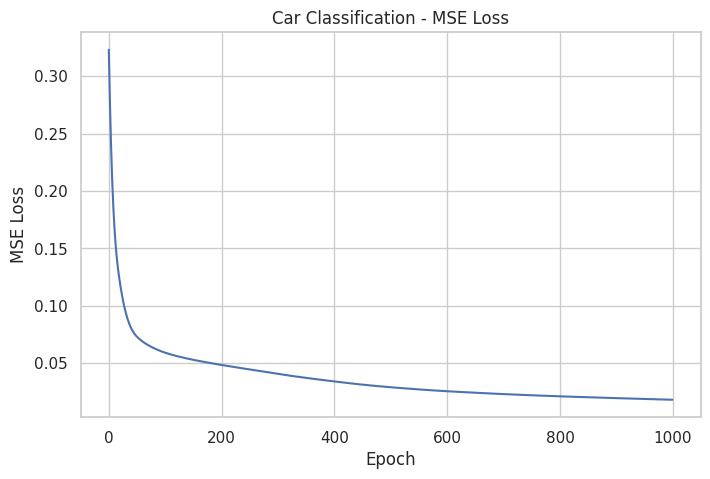

In [40]:
# epoch별 학습 Loss(MSE) 변화 그래프
plt.figure(figsize=(8, 5))

plt.plot(loss_history)                         # x축: epoch, y축: 해당 epoch의 Loss

plt.title("Car Classification - MSE Loss")
plt.xlabel("Epoch")                            # 학습 반복 횟수
plt.ylabel("MSE Loss")                         # 작을수록 예측이 정답에 가까움
plt.grid(True)
plt.show()

# 13. 전체 결과 비교

In [41]:
print(f"Baseline (전부 unacc) : {baseline_acc * 100:.2f}%")
print(f"Random Forest         : {rf_acc * 100:.2f}%")
print(f"인공신경망            : {accuracy * 100:.2f}%")

Baseline (전부 unacc) : 69.94%
Random Forest         : 96.53%
인공신경망            : 96.24%


# 14. 결과 분석

### (1) 결과 요약

- 두 모델 모두 Baseline(70%)보다 크게 높은 약 96%의 정확도
- 마지막 층 activation 없이 원-핫 정답과 MSE Loss로 학습해도 분류가 잘 됨

### (2) 정확도가 높은 이유
1. class가 입력 변수 6개만으로 정해지는 **규칙 기반 데이터** (예: safety가 low이거나 2인승이면 무조건 unacc)
2. 결측치, 중복이 없고 모든 조합이 한 번씩 들어있는 깔끔한 데이터

### (3) 부족한 점: 데이터가 적은 등급
- 전체 Accuracy는 높지만, **good(2)은 신경망 recall 약 57%, Random Forest 약 71%로 낮음**
- 이유: good과 vgood은 전체의 약 4%씩밖에 없어서 **학습 데이터가 부족함** (train에 good 55개, vgood 52개 정도)
- 모델이 데이터가 많은 unacc, acc 위주로 학습되어, 적은 등급은 이웃 등급으로 예측하는 경우가 생김
- 전체의 70%가 unacc라서 전체 Accuracy만 보면 적은 등급의 문제가 가려짐 → 클래스별 성능을 함께 확인해야 함

### (4) 회귀 실습과 비교
- 회귀(등급을 0~3 숫자로 예측 후 반올림): 신경망 약 98%, Decision Tree 약 98%
- 분류(원-핫으로 4개 클래스 예측): 신경망 약 96%, Random Forest 약 96.5%
- 두 방법 모두 비슷하게 높은 정확도 → 등급에 순서가 있어서 숫자로 바꿔 회귀로 풀어도 잘 맞힘
- 두 방법 모두 데이터가 적은 good 등급에서 가장 많이 틀림

### (5) 결론
자동차 평가 등급은 입력 변수 6개로 약 96%의 정확도로 분류할 수 있었다.
다만 데이터가 적은 good, vgood 등급은 정확도가 낮아서, 이 등급의 데이터가 더 있으면 성능을 높일 수 있다.